# Dataset class

This notebook shows some examples of how to use the `Dataset` class.

In [1]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt

import Dataset

# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = 'cpu'
print('device:', device)

device: cpu


First we read the data we want to work on. In this notebook we use a toy dataset wich consists in the $f(x)=x$ line.

In [2]:
# Read dataframe
df = pd.read_parquet('../Data/Toy Datasets/x_line.parquet')

# Extract NumPy arrays
X, y = df.values, df.values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.float32).to(device)
y = torch.tensor(y, dtype=torch.float32).to(device)

# Check the shape
print('Shape X:', X.shape)
print('Shape y:', y.shape)

Shape X: torch.Size([10000, 1])
Shape y: torch.Size([10000, 1])


## Shapes

Let:
- `SEQ_LEN_X` be 

### Regression without channels

(SEQ_LEN_X, n_features_x) -> (SEQ_LEN_Y, n_features_y)

### Regression with channels

(n_channels, SEQ_LEN_X, n_features_x) -> (n_channels, SEQ_LEN_Y, n_features_y)

### Classification without channels

(SEQ_LEN_X, n_features_x) -> (n_classes)

### Classification with channels

(n_channels, SEQ_LEN_X, n_features_x) -> (n_classes)

## First example

Now we define the three main parameters of the `Dataset` class:
- `seq_len_x`: the length of the input sequence
- `seq_len_y`: the length of the output sequence
- `offset`: the offset between the input and output sequences taken from the beginning of the `x` array. Therefore if `offset=0` the input and output sequences will be the same. If `offset=seq_len_x` the input and output sequences will be disjoint and the output sequence will in the future of the input sequence.

The dataset class generate itself the winddows using the `unfold` method from the PyTorch library.

In [5]:
SEQ_LEN_X = 100
SEQ_LEN_Y = 20
OFFSET = 100
dataset = Dataset.TimeSeriesDataset(
    X         = X,
    y         = y,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)

print(dataset.shape)

{'X': torch.Size([9900, 100, 1]), 'y': torch.Size([9900, 20, 1])}


Now we get the first point of the dataset, i.e. the first window.

In [6]:
# get first window
X_1, y_1 = dataset[0]

print('X_1:', X_1.shape)
print('y_1:', y_1.shape)

X_1: torch.Size([100, 1])
y_1: torch.Size([20, 1])


Finally we show a scatterplot of this first window.

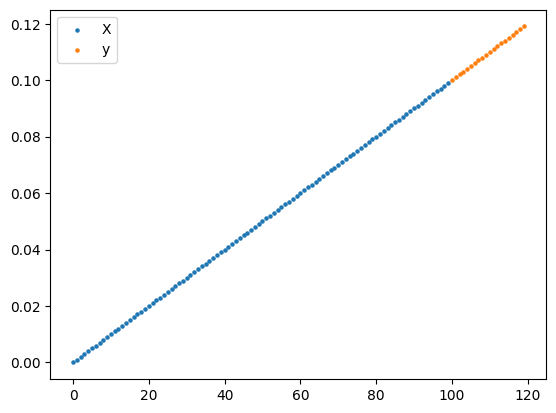

In [7]:
h1 = np.arange(0, X_1.shape[0])
h2 = np.arange(X_1.shape[0], X_1.shape[0]+y_1.shape[0])

plt.scatter(h1, X_1[:,0], label='X', s=5)
plt.scatter(h2, y_1[:,0], label='y', s=5)
plt.legend()
plt.show()

## Second example

In [8]:
SEQ_LEN_X = 50
SEQ_LEN_Y = 10
OFFSET = 40
dataset = Dataset.TimeSeriesDataset(
    X         = X,
    y         = y,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False
)

print(dataset.shape)

{'X': torch.Size([9950, 50, 1]), 'y': torch.Size([9950, 10, 1])}


In [9]:
# get first window
X_1, y_1 = dataset[0]

print('X_1:', X_1.shape)
print('y_1:', y_1.shape)

X_1: torch.Size([50, 1])
y_1: torch.Size([10, 1])


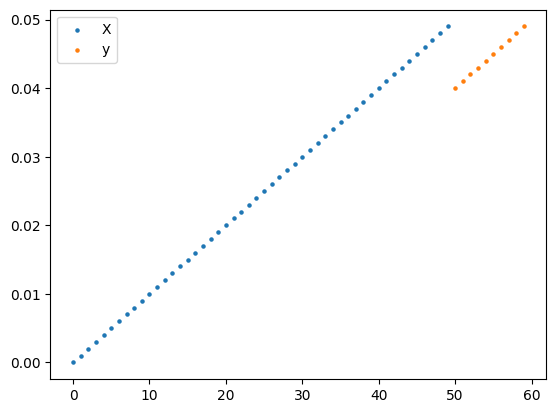

In [10]:
h1 = np.arange(0, X_1.shape[0])
h2 = np.arange(X_1.shape[0], X_1.shape[0]+y_1.shape[0])

plt.scatter(h1, X_1[:,0], label='X', s=5)
plt.scatter(h2, y_1[:,0], label='y', s=5)
plt.legend()
plt.show()